# T2I-VeRW data visualizer

Each record is one image with a caption (`captions`), a vehicle ID (`id`), a `split`, a 24×24 vehicle `mask`,
and a `boxes` file holding 24×24 part masks (windows, lights, wheels, mirrors, roof, doors).

In [9]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path('/mnt/data/ishant/datasets/T2I-VeRW')
data = json.load(open(ROOT / 'annotations/reid_with_mask_prompt_and_boxes_filepath_prefixid_idsplit_70_30.json'))
print(len(data), 'images')
print(data[0]['captions'][0])

14668 images
White SUV with a silver chrome grille containing horizontal bars and a central emblem, willow-leaf shaped headlights, five-spoke silver wheels, black roof rails along the roof edges, and a black sunroof panel; two blue illuminated daytime running lights are present on the lower front bumper, and a white tissue box is visible on the dashboard through the front windshield.


## Query text and its result images

The query is one image's caption. The correct results are all images with the same vehicle ID;
the image the caption describes is titled in red.

Query: Brown SUV with a black sunroof, horizontal grille featuring a central emblem, diamond-shaped headlights, and a white sticker along the lower edge of the front windshield. Two silver-colored inspection stickers are visible in the upper right corner of the windshield. Side mirrors are semi-oval shaped, and a red object is visible inside near the driver’s side.


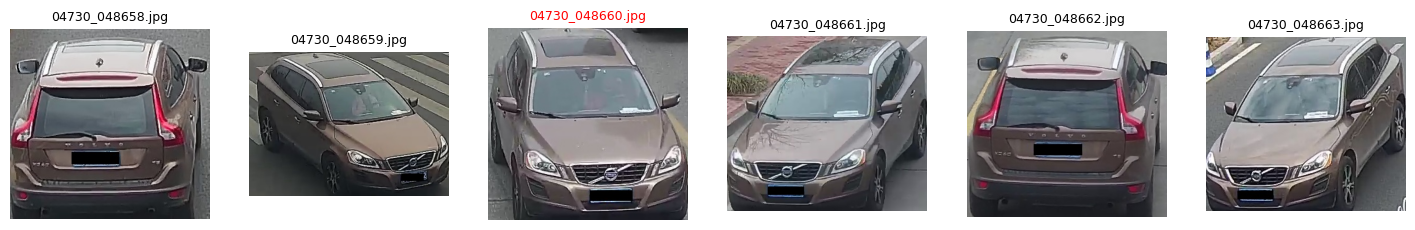

In [13]:
def show_query(i):
    q = data[i]
    results = [r for r in data if r['id'] == q['id']]
    print('Query:', q['captions'][0])

    fig, axes = plt.subplots(1, len(results), figsize=(3 * len(results), 3))
    for ax, r in zip(axes, results):
        ax.imshow(Image.open(ROOT / r['file_path']))
        ax.set_title(Path(r['file_path']).name, fontsize=9, color='red' if r is q else 'black')
        ax.axis('off')
    plt.show()


show_query(random.randrange(len(data)))

Find queries containing a word, then show one:

3636 captions mention sunroof
Query: White SUV with a silver chrome grille containing horizontal bars and a central emblem, willow-leaf shaped headlights, five-spoke silver wheels, black roof rails along the roof edges, and a black sunroof panel; two blue illuminated daytime running lights are present on the lower front bumper, and a white tissue box is visible on the dashboard through the front windshield.


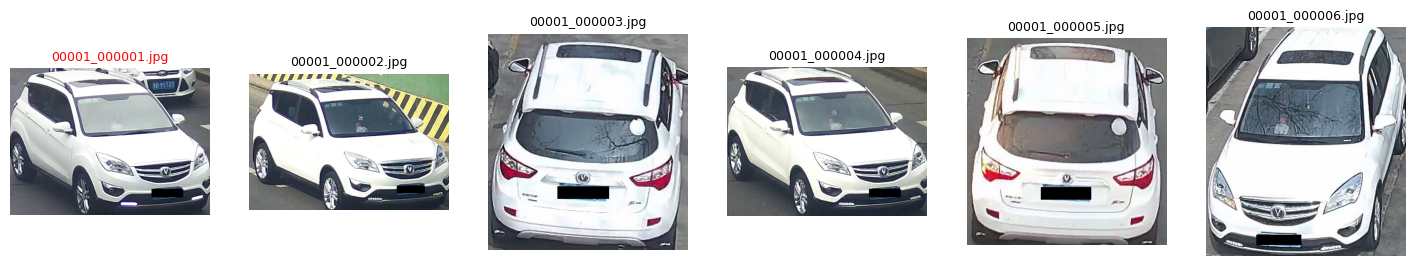

In [11]:
word = 'sunroof'
matches = [i for i, r in enumerate(data) if word in r['captions'][0].lower()]
print(len(matches), 'captions mention', word)
show_query(matches[0])

## Image and annotations

The 24×24 masks are stretched over the whole image (`extent`), with empty cells left transparent.

Caption: Black sedan with a horizontal grille, rectangular headlights with clear lenses, and five green inspection stickers arranged vertically in the upper right corner of the front windshield. A yellow rectangular object is visible on the dashboard near the windshield, and a small fin-shaped bump is present at the rear center of the roof. The wheels feature a multi-spoke design with a silver finish.
ID: 137 | split: train | prompt: A photo of a car.


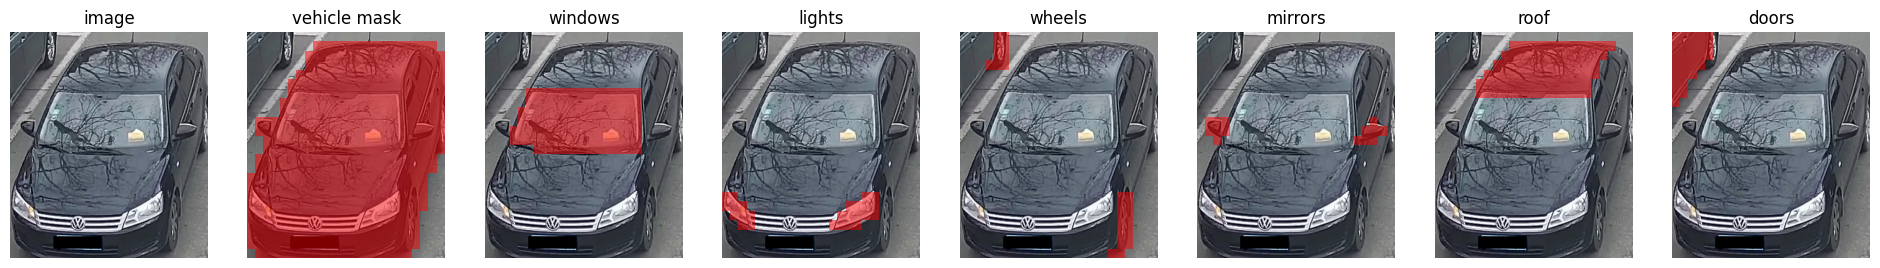

In [12]:
def show_annotations(i):
    r = data[i]
    img = Image.open(ROOT / r['file_path'])
    parts = json.load(open(ROOT / r['boxes']))
    print('Caption:', r['captions'][0])
    print('ID:', r['id'], '| split:', r['split'], '| prompt:', r['prompt'])

    panels = [('vehicle mask', r['mask'])] + [(p['category'], p['mask']) for p in parts]
    fig, axes = plt.subplots(1, len(panels) + 1, figsize=(3 * (len(panels) + 1), 3))
    axes[0].imshow(img)
    axes[0].set_title('image')
    for ax, (name, mask) in zip(axes[1:], panels):
        mask = np.array(mask)
        ax.imshow(img)
        ax.imshow(np.ma.masked_equal(mask, 0), cmap='autumn', alpha=0.5,
                  extent=(0, img.width, img.height, 0), interpolation='nearest')
        ax.set_title(name)
    for ax in axes:
        ax.axis('off')
    plt.show()


show_annotations(random.randrange(len(data)))

Caption: White SUV with a silver chrome grille containing horizontal bars and a central emblem, willow-leaf shaped headlights, five-spoke silver wheels, black roof rails along the roof edges, and a black sunroof panel; two blue illuminated daytime running lights are present on the lower front bumper, and a white tissue box is visible on the dashboard through the front windshield.
ID: 1 | split: val | prompt: A photo of a car.


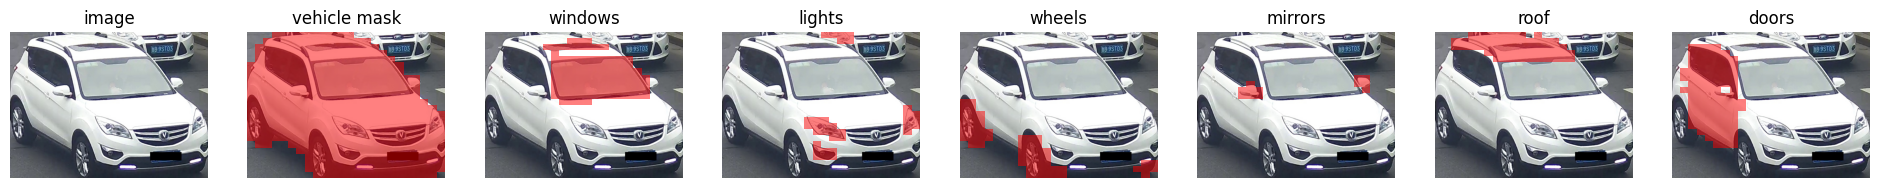

In [5]:
show_annotations(0)